# 02 — Expected behaviour: comparing sensor readings with reference values

**We compare the same later readings with different reference values.** For all eight signals, we calculate a median and an empirical range from the permitted reference readings, keep those numbers fixed, and measure departures later. For the two temperature signals, we also compare with the preceding five-second average. A separate, limited experiment examines the relationship between the vibration sensors.

| Term used in the outputs | What it means here |
|---|---|
| Fixed reference or baseline | A median and range used for comparison; they stay unchanged during application. |
| Fit or learn a fixed reference | **Calculate the median and 5th–95th percentiles from the permitted fitting readings.** No anomaly classifier is trained. |
| Local calibration | Use the recording's first 60 or 180 seconds for those calculations. This is a data-analysis step, not a physical sensor adjustment. |
| `expected` | The comparison value chosen by a method. For a fixed reference it is the median, not necessarily the mathematical mean or an engineering setpoint. |
| `residual` | **Observed value − reference value**, in the sensor's original units. Positive means above the reference; negative means below it. |

For example, 73°C compared with a 75°C reference gives a −2°C residual. The **median** is the middle value after sorting the readings. The **5th–95th percentile range** describes their middle 90% approximately. Repeated values can change the percentage included, and later readings need not have the same coverage.

Notebook 01 described the signals, differing starting levels and collection gaps. This notebook checks which references describe them usefully. Notebook 03 will decide which departures warrant alerts. A departure alone does not establish a fault.

We open the separate normal file and 26 development recordings; eight reserved recordings remain unopened. All files come from one testbed, and their timezone is unknown. The dictionary below lists all eight measurements; `gauge` means a measured level rather than a cumulative counter.

In [1]:
from pathlib import Path
from dataclasses import asdict
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import MaxNLocator

from ts_anomaly.skab import METRICS, load_development
from ts_anomaly.assessment import segment_acf
from ts_anomaly.baselines import (
    fit_reference, calibrate_reference, apply_reference, completed_gauges,
    persistence_prediction, compare_predictions, fit_pair_reference,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "configs/skab.json").exists(), "Open the repository or notebooks folder."
settings = json.loads((ROOT / "configs/skab.json").read_text())
options = settings["baselines"]
OUT = ROOT / "outputs/skab_baselines"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 3), "axes.grid": True, "grid.alpha": .2})
pd.set_option("display.max_columns", 14)
COLORS = {"separate_normal": "#777777", "local_60": "#0072B2",
          "local_180": "#D55E00", "persistence": "#009E73"}

def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

recordings, annotations = load_development(ROOT / "data/skab", settings)
manifest = pd.DataFrame(settings["files"])
reserved = set(manifest.loc[manifest.partition.eq("reserved_test"), "recording_id"])
assert reserved.isdisjoint(recordings)
normal_id = manifest.loc[manifest.partition.eq("reference"), "recording_id"].item()
development_ids = manifest.loc[manifest.partition.eq("development"), "recording_id"].tolist()
assert len(development_ids) == 26 and len(recordings) == 27
normal = recordings[normal_id].set_index("timestamp")
measurements = list(METRICS)
print(f"Opened {len(recordings)} recordings; {len(reserved)} reserved files excluded.")
display(pd.DataFrame({name: asdict(value) for name, value in METRICS.items()}).T[
    ["description", "unit", "kind"]])

Opened 27 recordings; 8 reserved files excluded.


,description,unit,kind
Accelerometer1RMS,"Vibration acceleration, sensor 1 (RMS)",g,gauge
Accelerometer2RMS,"Vibration acceleration, sensor 2 (RMS)",g,gauge
Current,Electric motor current,A,gauge
Pressure,Loop pressure after the pump,bar,gauge
Temperature,Motor body temperature,degC,gauge
Thermocouple,Circulating fluid temperature,degC,gauge
Voltage,Electric motor voltage,V,gauge
Volume Flow RateRMS,Circulating fluid flow rate,L/min,gauge


## 1. Which readings calculate each reference, and which check it?

| Method name in the tables | How its reference is calculated |
|---|---|
| `separate_normal` | Calculate one median and range per signal from the separate normal file, after checking that file's stability. Apply those same values to the development recordings. |
| `local_60` | Calculate a separate median and range for each signal from each development recording's first 60 seconds. |
| `local_180` | Do the same using each recording's first 180 seconds. |
| `persistence` | For temperature, use the previous completed five-second average to predict the next average. There is no fixed median to calculate for this method. |

For the local methods, the time boundaries are fixed in advance:

| Elapsed time in a recording | Local-60 | Local-180 | Use in comparison |
|---|---|---|---|
| 0–60 seconds | Calculate its reference | Part of its calculation period | Fitting only |
| 60–180 seconds | Reference is already available | Continue collecting fitting readings | Examine local-60's earlier availability separately |
| After 180 seconds | Apply unchanged reference | Apply unchanged reference | **Compare all three fixed methods on the same later readings** |

A reading exactly at a calibration cutoff is excluded from fitting and can be assessed afterward. Thus `[start, start + 60 seconds)` means include the start, exclude the endpoint. Calibration does not imply that the equipment physically starts up at the beginning of the file.

At least 80% of the nominal one-second slots must contain a finite measurement (neither missing nor infinite). A failed window remains unavailable; labels and future values never extend or repair it. This rule checks data coverage, not health or statistical precision.

The partition table below describes our project split, not an official SKAB split. The external file's date need not precede every experiment, so this tests transfer from a separate recording, not a chronological future deployment. Examples were chosen before comparing performance: `valve1/1`, `other/10` and gap-affected `other/2`. Folder names describe experiment families; they are not verified operating-state inputs.

In [2]:
protocols = pd.DataFrame([
    ["separate_normal", "Full separate normal file, after internal validation", "External-reference transfer"],
    ["local_60", "First 60 elapsed seconds; occupancy ≥80%", "Transfer after local calibration"],
    ["local_180", "First 180 elapsed seconds; occupancy ≥80%", "Transfer after longer calibration"],
    ["persistence", "Previous eligible, connected, completed five-second mean", "One-window-ahead thermal prediction"],
], columns=["method", "permitted_information", "question"])
display(protocols)
display(manifest.groupby("partition").size().rename("recordings").to_frame())
print("Calibration is half-open; a reading exactly at the cutoff is not fitted.")

,method,permitted_information,question
0,separate_normal,"Full separate normal file, after internal vali...",External-reference transfer
1,local_60,First 60 elapsed seconds; occupancy ≥80%,Transfer after local calibration
2,local_180,First 180 elapsed seconds; occupancy ≥80%,Transfer after longer calibration
3,persistence,"Previous eligible, connected, completed five-s...",One-window-ahead thermal prediction


,recordings
partition,
development,26
reference,1
reserved_test,8


Calibration is half-open; a reading exactly at the cutoff is not fitted.


### Are the separate files actually independent?

Different filenames can contain the same observations. The next table compares timestamps and all eight sensor readings with the normal file, using only opened recordings.

**Observed:** `other/5` repeats 572 complete sensor rows from that normal file. A reference calculated from the normal file has therefore already seen part of this experiment.

We still calculate the external reference from the full normal file, as specified. However, we exclude all of `other/5` when reporting independent external-reference comparisons. Its local-calibration and persistence comparisons remain included. Saved predictions flag this distinction with `transfer_eligible=False`; the recording partitions and reserved files are unchanged.

In [3]:
overlap_rows = []
for recording_id in development_ids:
    data = recordings[recording_id].set_index("timestamp")
    shared_times = normal.index.intersection(data.index)
    identical = normal.loc[shared_times, measurements].eq(data.loc[shared_times, measurements]).all(axis=1)
    overlap_rows.append({"recording_id": recording_id, "shared_timestamps": len(shared_times),
                         "identical_sensor_rows": int(identical.sum())})
reference_overlap = pd.DataFrame(overlap_rows)
overlap_ids = set(reference_overlap.loc[reference_overlap.identical_sensor_rows.gt(0), "recording_id"])
display(reference_overlap.loc[reference_overlap.shared_timestamps.gt(0)])
reference_overlap.to_csv(OUT / "reference_overlap.csv", index=False)
print("All 26 development experiments remain in local comparisons; independent external transfer excludes", sorted(overlap_ids))

,recording_id,shared_timestamps,identical_sensor_rows
7,other/5,572,572


All 26 development experiments remain in local comparisons; independent external transfer excludes ['other/5']


## 2. Does an earlier reference describe later readings in the normal file?

Before applying the normal-file reference elsewhere, check it within its own recording:

| Comparison | Calculate the median and range from | Assess them against |
|---|---|---|
| First check | First 50% of elapsed time | Following 25% |
| Second check | First 75% of elapsed time | Final 25% |

The percentages refer to **time**, not numbers of rows. We define the observation span to end one nominal second after the last reading. Later evaluation values never enter these reference calculations.

Use this guide for the table below:

| Column | How to read it |
|---|---|
| `fit_rows` | Number of readings used to calculate the reference. |
| `common` | Number of later readings used in the comparison. |
| `median_change` | Later median minus the earlier median; the direction and size of a level change. |
| `fit_iqr`, `evaluation_iqr` | Interquartile range (IQR): width of the middle 50% of values, before and after the time boundary. |
| `mae` | Mean absolute error: average distance from the reference, ignoring direction. |
| `bias` | Average signed residual: positive means readings tend to be above the reference. |
| `range_coverage` | Fraction of later values inside the earlier range, including its endpoints. Multiply by 100 for percent. |

MAE and bias retain the signal's units. They measure agreement with a reference, not anomaly-detection accuracy. Coverage near 90% is not guaranteed, including when fitting values are repeated.

In [4]:
normal_start = normal.index.min()
normal_end = normal.index.max() + pd.Timedelta(settings["nominal_interval"])
span = normal_end - normal_start
stability_rows, normal_blocks = [], []
for fit_fraction, end_fraction in [(0.5, .75), (.75, 1.0)]:
    cutoff = normal_start + span * fit_fraction
    end = normal_start + span * end_fraction
    for name in measurements:
        training = normal.loc[normal.index < cutoff, name]
        actual = normal.loc[(normal.index >= cutoff) & (normal.index < end), name]
        fitted = fit_reference(training)
        evaluated = fit_reference(actual)
        result = compare_predictions(actual, {"fixed": apply_reference(actual, fitted)})
        result = result.assign(measurement=name, fit_fraction=fit_fraction, fit_end=cutoff,
                               evaluation_end=end, fit_rows=len(training),
                               fit_median=fitted.expected, median_change=evaluated.expected - fitted.expected,
                               fit_iqr=fitted.iqr, evaluation_iqr=evaluated.iqr)
        stability_rows.append(result)
for block in range(8):
    start, end = normal_start + span * block / 8, normal_start + span * (block + 1) / 8
    for name in measurements:
        values = normal.loc[(normal.index >= start) & (normal.index < end), name]
        normal_blocks.append({"measurement": name, "block": block + 1,
                              "centre_minutes": ((start + (end-start)/2) - normal_start).total_seconds()/60,
                              "median": values.median(), "q25": values.quantile(.25), "q75": values.quantile(.75)})
stability = pd.concat(stability_rows, ignore_index=True)
blocks = pd.DataFrame(normal_blocks)

In [5]:
display(stability[["measurement", "fit_fraction", "fit_rows", "common", "median_change",
                   "fit_iqr", "evaluation_iqr", "mae", "bias", "range_coverage"]].round(4))
stability.to_csv(OUT / "normal_stability.csv", index=False)

,measurement,fit_fraction,fit_rows,common,median_change,fit_iqr,evaluation_iqr,mae,bias,range_coverage
0,Accelerometer1RMS,0.50,4653,2374,0.0042,0.0065,0.0044,0.0042,0.0041,0.4507
1,Accelerometer2RMS,0.50,4653,2374,-0.0044,0.0066,0.0023,0.0043,-0.0043,0.7325
2,Current,0.50,4653,2374,-0.0411,0.6074,0.6213,0.3696,-0.1697,0.9061
3,Pressure,0.50,4653,2374,0.0000,0.3279,0.3279,0.1702,0.0561,0.9398
4,Temperature,0.50,4653,2374,-0.7641,0.8952,0.4890,0.7302,-0.7302,0.5564
5,Thermocouple,0.50,4653,2374,0.9981,0.9480,0.2133,0.9609,0.9609,0.0017
6,Voltage,0.50,4653,2374,0.3045,12.3950,12.3055,8.2771,-0.1480,0.8947
7,Volume Flow RateRMS,0.50,4653,2374,2.3280,2.6690,1.0000,2.3545,2.3545,0.5644
8,Accelerometer1RMS,0.75,7027,2378,0.0019,0.0046,0.0058,0.0036,0.0019,0.8310
9,Accelerometer2RMS,0.75,7027,2378,-0.0026,0.0064,0.0039,0.0034,-0.0019,0.6716


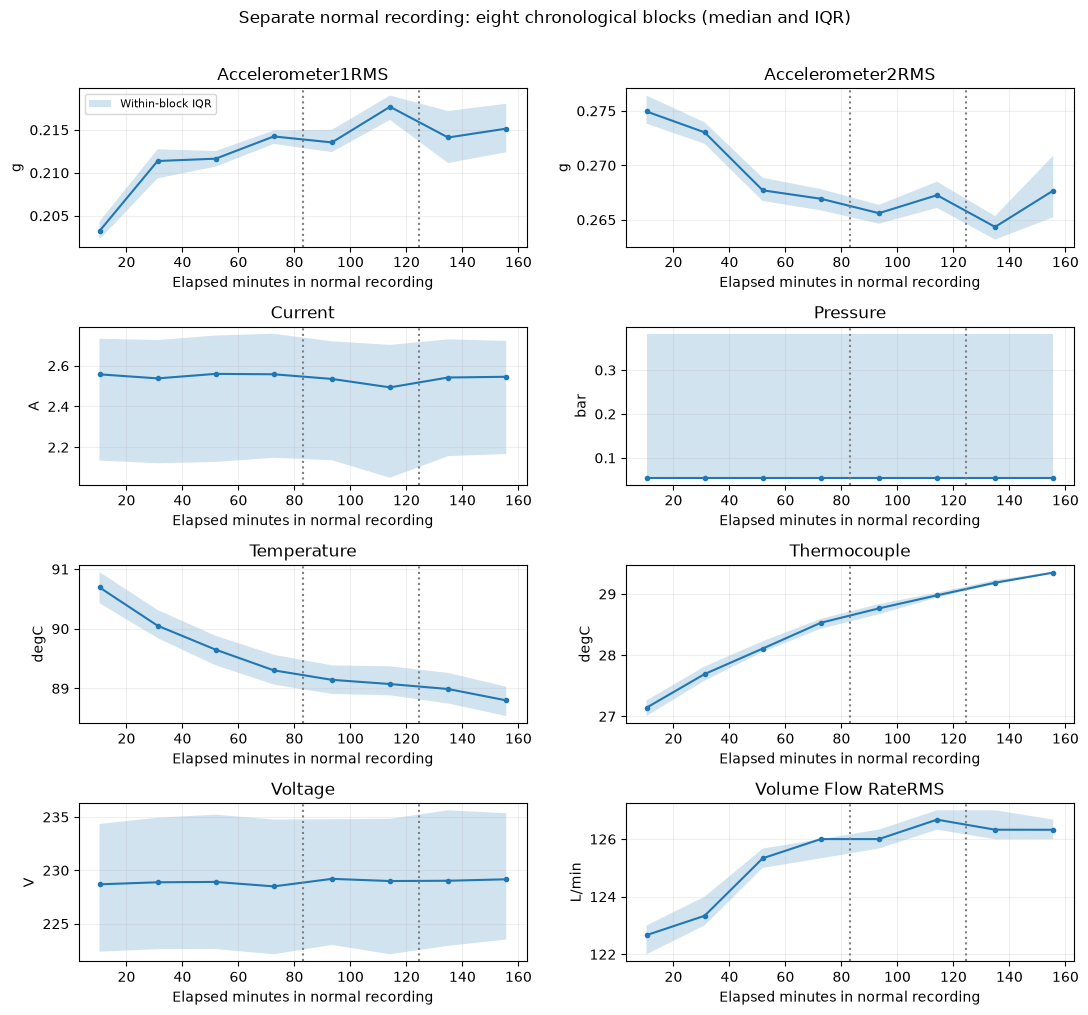

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(11, 10))
for ax, name in zip(axes.flat, measurements):
    view = blocks.loc[blocks.measurement.eq(name)]
    ax.plot(view.centre_minutes, view['median'], marker="o", markersize=3)
    ax.fill_between(view.centre_minutes, view.q25, view.q75, alpha=.2, label="Within-block IQR")
    for fraction in (.5, .75):
        ax.axvline(span.total_seconds()/60*fraction, color="grey", linestyle=":")
    ax.set(title=name, ylabel=METRICS[name].unit, xlabel="Elapsed minutes in normal recording")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Separate normal recording: eight chronological blocks (median and IQR)", y=1.01)
finish_figure(fig, "normal-stability")
normal_references = pd.DataFrame({name: fit_reference(normal[name]) for name in measurements}).T

**What the table and figure show:** the normal file's typical levels change over time. Fluid temperature rises while motor temperature falls.

For fluid temperature, the first-half reference covers only **0.17%** of readings in the next quarter; the first-75% reference covers **0%** of the final quarter. The later values have moved outside the earlier range. This does not establish faults in those readings. Motor-temperature coverage is about **56–57%**, while current and voltage coverage remains close to 90% in both checks.

In the figure, each point is the median of one chronological block. Shading contains that block's middle 50% of readings; it is not a confidence interval for the median. Dotted lines mark the 50% and 75% boundaries. Vibration and flow also change in typical level or spread.

**Implication:** even a file described as normal need not have constant behaviour. We now calculate the full-file median and range for the external-reference comparison, while retaining this limitation.

## 3. Are there enough readings in the first 60 or 180 seconds?

For each signal and recording, calculate the median and percentiles within both fixed windows. Then examine coverage, repeated values and changes between the first and second halves of each window. Annotations do not enter these calculations.

The first table checks availability:

| Column | Meaning |
|---|---|
| `observations` | Recorded finite readings within the window. |
| `occupied_seconds` | Nominal one-second slots with a finite reading. |
| `occupancy` | Occupied slots divided by 60 or 180. For example, 57/60 = 95%. |
| `supported_signals` | How many of the eight signals pass the 80% coverage rule. Eight means usable coverage for all; zero means none. |
| `gaps` | Intervals longer than two seconds between observations **inside** the selected window. |

The second table describes the calibration values across recordings:

| Column | Meaning |
|---|---|
| `smallest_distinct` | Fewest different values found in a calibration window. |
| `zero_mad` | Number of recordings with zero median absolute deviation (MAD): the median distance from the median is zero. This does not require every reading to be identical. |
| `collapsed_ranges` | Number whose lower and upper percentiles are identical. |
| `median_absolute_half_change` | Typical absolute difference between the medians of the two elapsed-time halves, in the signal's units. |

MAD describes spread around the calibration median; MAE measures later prediction error. A change between halves questions whether one fixed level describes the window, but does not automatically reject it. The saved detailed audit also includes missing slots and the repeat fraction, `1 − distinct values / finite observations`.

In [7]:
calibrations, calibration_rows = {}, []
for recording_id in development_ids:
    data = recordings[recording_id].set_index("timestamp")
    start = data.index.min()
    for seconds in options["calibration_seconds"]:
        end = start + pd.Timedelta(seconds=seconds)
        middle = start + (end-start)/2
        references = {}
        for name in measurements:
            fitted = calibrate_reference(data[name], start, end, options["minimum_occupancy"],
                                         settings["nominal_interval"])
            references[name] = fitted
            left = fit_reference(data.loc[(data.index >= start) & (data.index < middle), name])
            right = fit_reference(data.loc[(data.index >= middle) & (data.index < end), name])
            times = data.index[(data.index >= start) & (data.index < end)]
            row = fitted.to_dict()
            row.update(recording_id=recording_id, measurement=name, seconds=seconds,
                       missing_slots=fitted.expected_slots-fitted.occupied_slots,
                       repeated_fraction=1-fitted.distinct/fitted.observations if fitted.observations else np.nan,
                       half_median_change=right.expected-left.expected, half_iqr_change=right.iqr-left.iqr,
                       gaps=int(times.to_series().diff().gt(pd.Timedelta(settings["gap_threshold"])).sum()))
            calibration_rows.append(row)
        calibrations[recording_id, seconds] = pd.DataFrame(references).T
calibration = pd.DataFrame(calibration_rows)

In [8]:
support = calibration.groupby(["recording_id", "seconds"]).agg(
    observations=("observations", "min"), occupied_seconds=("occupied_slots", "min"),
    occupancy=("occupancy", "min"), supported_signals=("supported", "sum"), gaps=("gaps", "max"))
display(support.unstack("seconds").round(3))
display(calibration.groupby(["measurement", "seconds"]).agg(
    smallest_distinct=("distinct", "min"), zero_mad=("mad", lambda x: x.eq(0).sum()),
    collapsed_ranges=("collapsed_range", "sum"),
    median_absolute_half_change=("half_median_change", lambda x: x.abs().median())).round(5))
calibration.to_csv(OUT / "calibration_audit.csv", index=False)
normal_references.assign(fit_start=normal_start, fit_end=normal_end).to_csv(
    OUT / "separate_normal_references.csv", index_label="measurement")

observations      occupied_seconds      occupancy         \
seconds               60   180              60   180       60     180   
recording_id                                                            
other/1                57  172               57  172     0.950  0.956   
other/10               57  171               57  171     0.950  0.950   
other/11               58  172               58  172     0.967  0.956   
other/13               41  119               41  119     0.683  0.661   
other/14               58  172               58  172     0.967  0.956   
other/2                58  104               58  104     0.967  0.578   
other/3                58  171               58  171     0.967  0.950   
other/5                57  171               57  171     0.950  0.950   
other/6                58  172               58  172     0.967  0.956   
other/7                58  172               58  172     0.967  0.956   
other/9                58  172               58  172     0.967  0.956   
valve1/0               58  172               58  172     0.967  0.956   
valve1/1               57  171               57  171     0.950  0.950   
valve1/10              57  172               57  172     0.950  0.956   
valve1/12              57  171               57  171     0.950  0.950   
valve1/13              57  171               57  171     0.950  0.950   
valve1/14              57  170               57  170     0.950  0.944   
valve1/2               58  173               58  173     0.967  0.961   
valve1/4               58  173               58  173     0.967  0.961   
valve1/5               58  173               58  173     0.967  0.961   
valve1/6               57  173               57  173     0.950  0.961   
valve1/8               57  171               57  171     0.950  0.950   
valve1/9               58  172               58  172     0.967  0.956   
valve2/0               56  169               56  169     0.933  0.939   
valve2/1               56  168               56  168     0.933  0.933   
valve2/2               56  169               56  169     0.933  0.939   

             supported_signals     gaps      
seconds                    60  180  60  180  
recording_id                                 
other/1                      8   8    0   0  
other/10                     8   8    0   0  
other/11                     8   8    0   0  
other/13                     0   0    7  19  
other/14                     8   8    0   0  
other/2                      8   0    0   0  
other/3                      8   8    0   0  
other/5                      8   8    0   0  
other/6                      8   8    0   0  
other/7                      8   8    0   0  
other/9                      8   8    0   0  
valve1/0                     8   8    0   0  
valve1/1                     8   8    0   0  
valve1/10                    8   8    0   0  
valve1/12                    8   8    0   0  
valve1/13                    8   8    0   0  
valve1/14                    8   8    0   0  
valve1/2                     8   8    0   0  
valve1/4                     8   8    0   0  
valve1/5                     8   8    0   0  
valve1/6                     8   8    0   0  
valve1/8                     8   8    0   0  
valve1/9                     8   8    0   0  
valve2/0                     8   8    0   0  
valve2/1                     8   8    0   0  
valve2/2                     8   8    0   0

smallest_distinct  zero_mad  collapsed_ranges  \
measurement         seconds                                                  
Accelerometer1RMS   60                      41         0                 0   
                    180                    103         0                 0   
Accelerometer2RMS   60                      41         0                 0   
                    180                    103         0                 0   
Current             60                      41         0                 0   
                    180                    104         0                 0   
Pressure            60                       4        19                 0   
                    180                      4        23                 0   
Temperature         60                      41         0                 0   
                    180                    104         0                 0   
Thermocouple        60                      37         0                 0   
                    180                     86         0                 0   
Voltage             60                      41         0                 0   
                    180                    104         0                 0   
Volume Flow RateRMS 60                       3        10                 0   
                    180                      6        10                 0   

                             median_absolute_half_change  
measurement         seconds                               
Accelerometer1RMS   60                           0.00014  
                    180                          0.00010  
Accelerometer2RMS   60                           0.00032  
                    180                          0.00034  
Current             60                           0.13640  
                    180                          0.03446  
Pressure            60                           0.00000  
                    180                          0.00000  
Temperature         60                           0.22045  
                    180                          0.16240  
Thermocouple        60                           0.00825  
                    180                          0.01715  
Voltage             60                           2.09300  
                    180                          0.61100  
Volume Flow RateRMS 60                           0.00000  
                    180                          0.00000

**The next two outputs answer different questions.** First, the annotation audit counts recorded anomaly and changepoint labels inside the already fixed calibration windows; it never changes the reference. Then the centre-change table reports `180-second median − 60-second median` for each recording and summarises those differences. A positive value means longer calibration gives a higher reference, not necessarily a better one.

In [9]:
# These annotations audit estimates already fixed above; they never alter them.
contamination_rows = []
phases = {}
for recording_id in development_ids:
    labels = annotations[recording_id].set_index("timestamp")
    marked = labels.anomaly.eq(1) | labels.changepoint.eq(1)
    first_mark = labels.index[marked].min()
    phases[recording_id] = pd.Series(np.select(
        [labels.anomaly.eq(1), labels.changepoint.eq(1), labels.index < first_mark],
        ["labelled_anomaly", "transition_only", "before_first_mark"],
        default="later_label_zero"), index=labels.index, name="phase")
    start = labels.index.min()
    for seconds in options["calibration_seconds"]:
        selected = labels.loc[labels.index < start + pd.Timedelta(seconds=seconds)]
        contamination_rows.append({"recording_id": recording_id, "seconds": seconds,
                                   "observed_anomaly_rows": int(selected.anomaly.sum()),
                                   "observed_transition_rows": int(selected.changepoint.sum()),
                                   "first_mark_elapsed_s": (first_mark-start).total_seconds()})
contamination = pd.DataFrame(contamination_rows)
display(contamination.groupby("seconds")[["observed_anomaly_rows", "observed_transition_rows"]].sum())
print("Earliest first marked change (seconds):", contamination.first_mark_elapsed_s.min())
contamination.to_csv(OUT / "calibration_label_audit.csv", index=False)

calibration_centres = calibration.pivot(index=["recording_id", "measurement"], columns="seconds", values="expected")
calibration_centres["change_180_minus_60"] = calibration_centres[180] - calibration_centres[60]
display(calibration_centres.groupby("measurement").change_180_minus_60.agg(["min", "median", "max"]).round(5))

,observed_anomaly_rows,observed_transition_rows
seconds,,
60,0,0
180,0,0


Earliest first marked change (seconds): 354.0


,min,median,max
measurement,,,
Accelerometer1RMS,-0.00158,0.00003,0.00119
Accelerometer2RMS,-0.00125,-0.00000,0.00071
Current,-0.16590,-0.05799,0.32622
Pressure,0.00000,0.00000,0.00000
Temperature,-1.30410,0.03388,0.60780
Thermocouple,-0.03645,-0.00075,0.03310
Voltage,-1.26800,-0.10675,2.43250
Volume Flow RateRMS,-0.15650,0.00000,1.20550


**Reading the pressure-level table:** `value` is a recorded pressure level, `observations` counts its occurrences, and `fraction` is its share of the normal file. Repeated levels explain why MAD can be zero despite some variation. Negative values are retained because the source does not establish calibrated validity limits that justify deleting them.

In [10]:
# Recorded levels are informative even when a robust scale is zero.
level_rows = []
for recording_id in [normal_id, *development_ids]:
    for name in ["Pressure", "Volume Flow RateRMS"]:
        values = recordings[recording_id][name]
        counts = values.value_counts().rename_axis("value").reset_index(name="observations")
        level_rows.append(counts.assign(recording_id=recording_id, measurement=name,
                                       fraction=counts.observations/len(values)))
levels = pd.concat(level_rows, ignore_index=True)
levels.to_csv(OUT / "recorded_levels.csv", index=False)
display(levels.loc[levels.recording_id.eq(normal_id) & levels.measurement.eq("Pressure")].round(6))

,value,observations,recording_id,measurement,fraction
0,0.054711,5165,anomaly-free/anomaly-free,Pressure,0.549176
1,0.382638,2489,anomaly-free/anomaly-free,Pressure,0.264646
2,-0.273216,1228,anomaly-free/anomaly-free,Pressure,0.130569
3,0.710565,347,anomaly-free/anomaly-free,Pressure,0.036895
4,-0.601143,165,anomaly-free/anomaly-free,Pressure,0.017544
5,-0.929070,4,anomaly-free/anomaly-free,Pressure,0.000425
6,1.038490,3,anomaly-free/anomaly-free,Pressure,0.000319
7,1.366420,2,anomaly-free/anomaly-free,Pressure,0.000213
8,-1.257000,2,anomaly-free/anomaly-free,Pressure,0.000213


**Observed:** local-60 has sufficient coverage in **25/26 recordings**. `other/13` fails with 41/60 occupied seconds. Local-180 supports **24/26**: `other/13` has 119/180 and `other/2` has 104/180. All eight signals share these failures because the source rows contain all eight measurements.

Why does `other/2` show zero internal gaps but insufficient 180-second coverage? Its observations stop before the calibration window ends. The empty tail lowers occupancy, even though the table finds no long interval between two observations *inside* that window. A zero gap count alone does not establish complete recording.

Neither calibration window contains an observed positive anomaly or changepoint label; the earliest first mark is at 354 seconds. This is a check made afterward, not a way of selecting healthy fitting data. Gaps and limited annotations still leave uncertainty.

Pressure has zero MAD in 19/26 short and 23/26 longer windows; flow has zero MAD in 10/26 for either duration. None of these percentile ranges collapses. We retain residuals in original units, avoiding division by a zero MAD. More observations can change the reference without necessarily improving it.

## 4. Which fixed reference describes the same later readings better?

Keep each calculated median and range unchanged. For every signal, compare the three references against the **same recorded readings after 180 seconds**. Here, `native` means the original sensor samples, before averaging into five-second windows.

A real example makes the comparison concrete. Six minutes into `valve1/1`, the motor temperature is **73.0509°C**:

| Reference | Where its median came from | Median (°C) | Same observed value minus median (°C) |
|---|---|---:|---:|
| Separate normal | Separate normal recording | 89.3515 | −16.3006 |
| Local-60 | This recording's first 60 seconds | 75.6128 | −2.5619 |
| Local-180 | This recording's first 180 seconds | 75.8308 | −2.7799 |

The observation stays the same; the comparison value changes. Local-60 is closest at this instant. We repeat the calculation over later readings to assess the whole interval, rather than choose a method from one point.

Each recording receives its own error summary. We then summarise those results across recordings, giving each recording one vote. We do not pool errors from different measurement units. A smaller average departure indicates a closer description; it does not establish better fault detection.

In [11]:
native_predictions, native_rows, phase_rows, early_rows, residual_rows = {}, [], [], [], []
local_rows = []
for recording_id in development_ids:
    data = recordings[recording_id].set_index("timestamp")
    start = data.index.min()
    common_start = start + pd.Timedelta(seconds=180)
    for name in measurements:
        actual = data[name]
        predictions = {"separate_normal": apply_reference(actual, normal_references.loc[name])}
        for seconds in options["calibration_seconds"]:
            predictions[f"local_{seconds}"] = apply_reference(
                actual, calibrations[recording_id, seconds].loc[name],
                available_from=start + pd.Timedelta(seconds=seconds))
        native_predictions[recording_id, name] = predictions
        later = actual.index >= common_start
        comparison_mask = pd.Series(recording_id not in overlap_ids, index=actual.loc[later].index)
        compared = compare_predictions(actual.loc[later], {k: v.loc[later] for k, v in predictions.items()}, comparison_mask)
        local_result = compare_predictions(actual.loc[later], {k: predictions[k].loc[later] for k in ["local_60", "local_180"]})
        local_rows.append(local_result.assign(recording_id=recording_id, measurement=name))
        native_rows.append(compared.assign(recording_id=recording_id, measurement=name))
        for phase in phases[recording_id].unique():
            selected = later & phases[recording_id].eq(phase)
            mask = pd.Series(recording_id not in overlap_ids, index=actual.loc[selected].index)
            result = compare_predictions(actual.loc[selected], {k: v.loc[selected] for k, v in predictions.items()}, mask)
            phase_rows.append(result.assign(recording_id=recording_id, measurement=name, phase=phase))
        early = (actual.index >= start + pd.Timedelta(seconds=60)) & (actual.index < common_start)
        mask = pd.Series(recording_id not in overlap_ids, index=actual.loc[early].index)
        result = compare_predictions(actual.loc[early], {k: predictions[k].loc[early] for k in ["separate_normal", "local_60"]}, mask)
        early_rows.append(result.assign(recording_id=recording_id, measurement=name))
        for method, prediction in predictions.items():
            view = prediction.loc[actual.index >= start + pd.Timedelta(seconds=60)].copy()
            view["actual"] = actual.reindex(view.index)
            view["eligible"] = np.isfinite(view.actual) & np.isfinite(view.expected)
            view["phase"] = phases[recording_id].reindex(view.index)
            residual_rows.append(view.assign(recording_id=recording_id, measurement=name, method=method,
                                             unit=METRICS[name].unit, transfer_eligible=recording_id not in overlap_ids).reset_index())

In [12]:
native_results = pd.concat(native_rows, ignore_index=True)
local_results = pd.concat(local_rows, ignore_index=True)
local_results.to_csv(OUT / "local_calibration_comparisons.csv", index=False)
phase_results = pd.concat(phase_rows, ignore_index=True)
early_results = pd.concat(early_rows, ignore_index=True)
native_residuals = pd.concat(residual_rows, ignore_index=True)
for table, filename in [(native_results, "native_comparisons"), (phase_results, "native_by_annotation"),
                        (early_results, "early_availability")]:
    table.to_csv(OUT / f"{filename}.csv", index=False)
native_residuals.to_csv(OUT / "native_residuals.csv.gz", index=False, compression="gzip")

**Reading the comparison table:** `compared_recordings` counts recordings with readings assessable by all three methods. `median_mae`, `median_bias`, `median_coverage` and `median_width` are medians of recording-level results; width is upper minus lower limit, in the signal's units.

`availability` has a different denominator: it averages scorable availability across all 26 development recordings. Here, local-60's 0.96154 is 25/26 and local-180's 0.92308 is 24/26. It does not measure how completely elapsed time was recorded. Detailed files also report each method's own-observation errors and `common`, the number of shared evaluation readings. An unsupported method can leave the common comparison empty even when another method produces values.

In [13]:
summary = native_results.groupby(["measurement", "method"]).agg(
    compared_recordings=("mae", "count"), availability=("availability", "mean"),
    median_mae=("mae", "median"), median_bias=("bias", "median"),
    median_coverage=("range_coverage", "median"), median_width=("range_width", "median"))
display(summary.round(5))
print("Complete per-recording results and residuals are saved under", OUT.relative_to(ROOT))

compared_recordings  availability  \
measurement         method                                               
Accelerometer1RMS   local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   
Accelerometer2RMS   local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   
Current             local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   
Pressure            local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   
Temperature         local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   
Thermocouple        local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   
Voltage             local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   
Volume Flow RateRMS local_180                         23       0.92308   
                    local_60                          23       0.96154   
                    separate_normal                   23       1.00000   

                                     median_mae  median_bias  median_coverage  \
measurement         method                                                      
Accelerometer1RMS   local_180           0.00038      0.00003          0.82059   
                    local_60            0.00040      0.00007          0.75000   
                    separate_normal     0.18547     -0.18547          0.00000   
Accelerometer2RMS   local_180           0.00102      0.00036          0.77880   
                    local_60            0.00111      0.00039          0.76283   
                    separate_normal     0.22664     -0.22664          0.00000   
Current             local_180           0.23957     -0.02575          0.89096   
                    local_60            0.25813     -0.08741          0.86492   
                    separate_normal     1.55620     -1.55620          0.09870   
Pressure            local_180           0.16635      0.01483          0.94346   
                    local_60            0.16635      0.01483          0.94530   
                    separate_normal     0.16635      0.01483          0.94118   
Temperature         local_180           0.92015     -0.44408          0.20330   
                    local_60            0.93334     -0.31951          0.11831   
                    separate_normal    18.42097    -18.42097          0.00000   
Thermocouple        local_180           0.05823     -0.02789          0.26458   
                    local_60            0.07403     -0.03727          0.10312   
                    separate_normal     3.63723     -3.63723          0.00000   
Voltage             local_180           8.16630     -0.35512          0.89696   
                    local_60            8.21147     -0.64663          0.85626   
                    separate_normal     8.44208      1.51860          0.90256   
Volume Flow RateRMS local_180           0.88602     -0.60149          0.59133   
                    local_60            0.88602     -0.60626          0.59133   
                    separate_normal    93.79192    -93.79192          0.00000   

     

Complete per-recording results and residuals are saved under outputs/skab_baselines


**First output: compare methods within each recording.** `local60_minus_separate` means MAE(local-60) minus MAE(separate-normal); `local180_minus_local60` is defined similarly. Negative means smaller error. Calculate the difference in each recording before taking its median: this need not equal the difference of the two methods' separately reported medians. The counts differ because only the external comparison excludes `other/5`.

**Second output: examine seconds 60–180.** Local-60 can already produce values while local-180 is still collecting fitting data. `available_rows` counts scorable results; `recorded_rows` counts observations that actually exist in that interval. Neither counts unrecorded seconds.

In [14]:
# Paired differences, calculated within a recording before summarising recordings.
paired = native_results.pivot(index=["recording_id", "measurement"], columns="method", values="mae")
paired["local60_minus_separate"] = paired.local_60 - paired.separate_normal
local_paired = local_results.pivot(index=["recording_id", "measurement"], columns="method", values="mae")
paired["local180_minus_local60"] = local_paired.local_180 - local_paired.local_60
display(paired.groupby("measurement")[["local60_minus_separate", "local180_minus_local60"]].agg(
    ["count", "min", "median", "max"]).round(5))
print("Negative paired MAE changes mean smaller errors, not better fault detection.")
display(early_results.groupby(["measurement", "method"]).agg(
    available_rows=("available", "sum"), recorded_rows=("requested", "sum"),
    comparable_recordings=("mae", "count"), median_mae=("mae", "median")).round(4))

method              local60_minus_separate                               \
                                     count       min    median      max   
measurement                                                               
Accelerometer1RMS                       23  -0.18608  -0.18511  0.00055   
Accelerometer2RMS                       23  -0.22705  -0.22543  0.00104   
Current                                 23  -1.33894  -1.30310  0.05572   
Pressure                                23   0.00000   0.00000  0.00000   
Temperature                             23 -20.88979 -17.77611 -0.34613   
Thermocouple                            23  -6.51552  -3.55520 -0.09452   
Voltage                                 23  -0.33401  -0.16272  0.14552   
Volume Flow RateRMS                     23 -93.59077 -93.21198 -0.05817   

method              local180_minus_local60                             
                                     count      min   median      max  
measurement                                                            
Accelerometer1RMS                       24 -0.00063 -0.00002  0.00081  
Accelerometer2RMS                       24 -0.00035 -0.00002  0.00049  
Current                                 24 -0.06024 -0.01200  0.00090  
Pressure                                24  0.00000  0.00000  0.00000  
Temperature                             24 -0.34173  0.00128  0.92803  
Thermocouple                            24 -0.03116 -0.00218  0.03098  
Voltage                                 24 -0.43782 -0.01847  0.04926  
Volume Flow RateRMS                     24 -0.33642  0.00000  0.00007

Negative paired MAE changes mean smaller errors, not better fault detection.


available_rows  recorded_rows  \
measurement         method                                           
Accelerometer1RMS   local_60                   2783           2861   
                    separate_normal            2861           2861   
Accelerometer2RMS   local_60                   2783           2861   
                    separate_normal            2861           2861   
Current             local_60                   2783           2861   
                    separate_normal            2861           2861   
Pressure            local_60                   2783           2861   
                    separate_normal            2861           2861   
Temperature         local_60                   2783           2861   
                    separate_normal            2861           2861   
Thermocouple        local_60                   2783           2861   
                    separate_normal            2861           2861   
Voltage             local_60                   2783           2861   
                    separate_normal            2861           2861   
Volume Flow RateRMS local_60                   2783           2861   
                    separate_normal            2861           2861   

                                     comparable_recordings  median_mae  
measurement         method                                              
Accelerometer1RMS   local_60                            24      0.0004  
                    separate_normal                     24      0.1855  
Accelerometer2RMS   local_60                            24      0.0008  
                    separate_normal                     24      0.2268  
Current             local_60                            24      0.2916  
                    separate_normal                     24      1.5387  
Pressure            local_60                            24      0.1582  
                    separate_normal                     24      0.1582  
Temperature         local_60                            24      0.3048  
                    separate_normal                     24     17.1898  
Thermocouple        local_60                            24      0.0197  
                    separate_normal                     24      3.6758  
Voltage             local_60                            24      8.0997  
                    separate_normal                     24      8.3517  
Volume Flow RateRMS local_60                            24      0.2918  
                    separate_normal                     24     93.4662

**Before the first marked change:** the next table uses only later readings after 180 seconds and before the first supplied anomaly or changepoint mark. It checks whether a reference is already inappropriate before a labelled intervention. This is a retrospective description, not proof that these readings are healthy. Full saved results also distinguish anomaly-labelled, transition-only and later label-zero portions.

In [15]:
phase_summary = phase_results.groupby(["measurement", "phase", "method"]).agg(
    recordings=("mae", "count"), median_mae=("mae", "median"),
    median_bias=("bias", "median"), median_coverage=("range_coverage", "median"))
display(phase_summary.loc[(slice(None), "before_first_mark", slice(None)), :].round(5))
phase_summary.to_csv(OUT / "native_annotation_summary.csv")

recordings  median_mae  \
measurement         phase             method                                    
Accelerometer1RMS   before_first_mark local_180                23     0.00037   
                                      local_60                 23     0.00037   
                                      separate_normal          23     0.18548   
Accelerometer2RMS   before_first_mark local_180                23     0.00096   
                                      local_60                 23     0.00096   
                                      separate_normal          23     0.22662   
Current             before_first_mark local_180                23     0.24078   
                                      local_60                 23     0.26057   
                                      separate_normal          23     1.54646   
Pressure            before_first_mark local_180                23     0.16478   
                                      local_60                 23     0.16478   
                                      separate_normal          23     0.16478   
Temperature         before_first_mark local_180                23     0.72108   
                                      local_60                 23     0.77363   
                                      separate_normal          23    18.62654   
Thermocouple        before_first_mark local_180                23     0.02551   
                                      local_60                 23     0.04108   
                                      separate_normal          23     3.59326   
Voltage             before_first_mark local_180                23     8.16823   
                                      local_60                 23     8.17989   
                                      separate_normal          23     8.26091   
Volume Flow RateRMS before_first_mark local_180                23     0.30083   
                                      local_60                 23     0.33637   
                                      separate_normal          23    93.43195   

                                                       median_bias  \
measurement         phase             method                         
Accelerometer1RMS   before_first_mark local_180            0.00001   
                                      local_60             0.00003   
                                      separate_normal     -0.18548   
Accelerometer2RMS   before_first_mark local_180            0.00010   
                                      local_60             0.00030   
                                      separate_normal     -0.22662   
Current             before_first_mark local_180           -0.02896   
                                      local_60            -0.07950   
                                      separate_normal     -1.54646   
Pressure            before_first_mark local_180            0.01554   
                                      local_60             0.01554   
                                      separate_normal      0.01554   
Temperature         before_first_mark local_180           -0.16671   
                                      local_60            -0.20101   
                                      separate_normal    -18.62654   
Thermocouple        before_first_mark local_180           -0.01270   
                                      local_60            -0.02075   
                                      separate_normal     -3.59326   
Voltage             before_first_mark local_180           -0.18230   
                                      local_60            -0.35196   
                                      separate_normal      1.38428   
Volume Flow RateRMS before_first_mark local_180            0.03048   
                                      local_60             0.03048   
                                      separate_normal    -93.43195   

                                                       median_coverage  
measurement         phase             method          

**Reading the next figure:** black shows measured values; grey is the separate-normal median; blue is local-60; orange is local-180. Blue shading shows the local-60 empirical range, and the dotted vertical line marks three minutes. Each row is a different recording. Reference lines remain fixed; sensor traces break at known collection gaps.

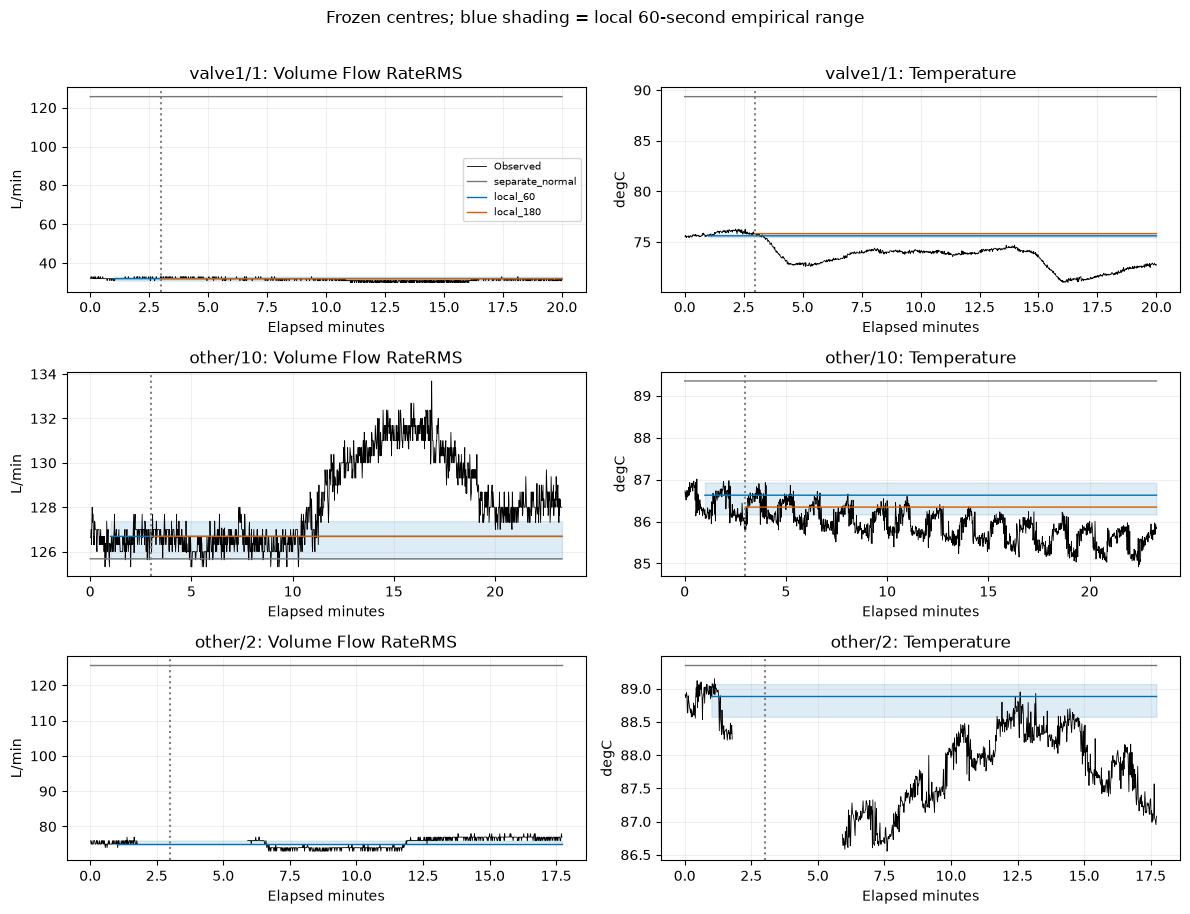

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for row, recording_id in enumerate(options["examples"]):
    data = recordings[recording_id].set_index("timestamp")
    elapsed = (data.index - data.index.min()).total_seconds()/60
    for col, name in enumerate(["Volume Flow RateRMS", "Temperature"]):
        ax = axes[row, col]
        # Break native traces at known collection gaps instead of joining them.
        observed = data[name].where(data.index.to_series().diff().le(pd.Timedelta(settings["gap_threshold"])))
        ax.plot(elapsed, observed, color="black", linewidth=.6, label="Observed")
        for method, prediction in native_predictions[recording_id, name].items():
            ax.plot(elapsed, prediction.expected, color=COLORS[method], label=method, linewidth=1)
            if method == "local_60":
                ax.fill_between(elapsed, prediction.lower, prediction.upper, color=COLORS[method], alpha=.13)
        ax.axvline(3, color="grey", linestyle=":")
        ax.set(title=f"{recording_id}: {name}", ylabel=METRICS[name].unit, xlabel="Elapsed minutes")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Frozen centres; blue shading = local 60-second empirical range", y=1.01)
finish_figure(fig, "fixed-transfer")

**Observed:** the three-method comparison contains **23 recordings**: the two local-180 coverage failures and the overlapping `other/5` are excluded from its errors. The local-60/local-180 comparison contains **24**, because it can include `other/5`.

Across the 23 shared external/local cases, the median recording-level flow MAE falls from **93.79 L/min** with the external reference to **0.886 L/min** with local-60. Motor-temperature MAE falls from **18.42°C to 0.933°C**. This largely removes differences in starting levels. The pre-marked table shows that mismatch already exists before labelled interventions. Pressure medians give identical errors; voltage improvements are modest.

A closer median does not guarantee a useful range. Local-60 covers only about **12%** of later motor temperatures and **10%** of fluid temperatures in the independent full-interval comparison. Their behaviour moves beyond the narrow initial ranges.

Longer calibration is not consistently better. Across the 24 paired local comparisons, the median current MAE change is **−0.012 A**, but motor-temperature changes span **−0.342 to +0.928°C**. Negative means a reduction in error; positive means an increase.

In `other/2`, the orange local-180 line is absent because calibration fails. The blue local-60 reference remains unchanged after the collection gap. That line supplies a comparison level, not replacement sensor observations.

## 5. Does the previous five-second average describe temperature better?

For `Temperature` and `Thermocouple`, compare the fixed references with a simple prediction: **use the preceding five-second average as the prediction for the next average**. This method is called persistence.

| Time | Information available |
|---|---|
| At 12:00:05 | Readings from 12:00:00 up to, but excluding, 12:00:05 can form the first average. |
| At 12:00:05 | Use that completed average to predict the 12:00:05–12:00:10 average. |
| At 12:00:10 | The next window has finished; assess the prediction if its data and continuity are adequate. |

Each average requires at least four finite readings. Missing measurements, insufficiently observed windows or raw collection gaps longer than two seconds can make the residual unavailable. A forecast may already have been issued before an unexpected gap is known: its expected value remains in the audit output, but `eligible=False` excludes it from scoring. Empty windows are never filled with the last reading, and history never crosses recording boundaries.

**Keep the comparison fair:** recalculate the fixed medians and ranges using five-second averages from the same permitted fitting periods. Compare these references and persistence against the same later averages. Local references still require 80% native calibration coverage; incomplete edge windows are omitted. We do not create a prediction range for persistence.

Assessment windows start at or after 180 seconds. The four-method comparison is supplemented by a local-60/persistence comparison, which does not require a successful local-180 reference.

In [17]:
thermal = ["Temperature", "Thermocouple"]
frequency = options["aggregation_interval"]
step = pd.Timedelta(frequency)
aggregates, continuity, aggregate_counts = {}, {}, {}
for recording_id, data in recordings.items():
    means, counts, connected = completed_gauges(
        data, measurements, frequency, options["minimum_bin_observations"],
        settings["gap_threshold"], settings["nominal_interval"])
    aggregates[recording_id], aggregate_counts[recording_id], continuity[recording_id] = means, counts, connected
aggregate_normal = pd.DataFrame({name: fit_reference(aggregates[normal_id][name]) for name in thermal}).T
aggregate_normal.to_csv(OUT / "aggregate_normal_references.csv", index_label="measurement")

In [18]:
thermal_predictions, thermal_rows, thermal_pair_rows, thermal_phase_rows = {}, [], [], []
thermal_residual_rows, aggregate_fit_rows, temporal_support = [], [], []
for recording_id in development_ids:
    means, connected = aggregates[recording_id], continuity[recording_id]
    start = recordings[recording_id].timestamp.min()
    later = means.index - step >= start + pd.Timedelta(seconds=180)
    # Annotations are attached only to already constructed targets/predictions.
    native_phase = phases[recording_id]
    groups = native_phase.resample(frequency, closed="left", label="left")
    phase = groups.first().where(groups.nunique().eq(1), "mixed")
    transitions = annotations[recording_id].set_index("timestamp").changepoint.resample(frequency).max()
    phase = phase.mask(transitions.eq(1), "transition_or_mixed")
    phase.index += step
    phase = phase.reindex(means.index)
    for name in thermal:
        actual = means[name]
        predictions = {"separate_normal": apply_reference(actual, aggregate_normal.loc[name])}
        for seconds in options["calibration_seconds"]:
            cutoff = start + pd.Timedelta(seconds=seconds)
            selected = (means.index - step >= start) & (means.index <= cutoff)
            fitted = fit_reference(actual.loc[selected])
            fitted.supported = bool(fitted.supported and calibrations[recording_id, seconds].loc[name, "supported"])
            predictions[f"local_{seconds}"] = apply_reference(actual, fitted, available_from=cutoff+step)
            aggregate_fit_rows.append(dict(recording_id=recording_id, measurement=name, seconds=seconds,
                                           fit_start=start, fit_end=cutoff, **fitted.to_dict()))
        predictions["persistence"] = persistence_prediction(actual, connected[name], frequency)
        thermal_predictions[recording_id, name] = predictions
        mask = pd.Series(recording_id not in overlap_ids, index=actual.loc[later].index)
        result = compare_predictions(actual.loc[later], {k: v.loc[later] for k, v in predictions.items()}, mask)
        thermal_rows.append(result.assign(recording_id=recording_id, measurement=name))
        pair = {k: predictions[k].loc[later] for k in ["local_60", "persistence"]}
        thermal_pair_rows.append(compare_predictions(actual.loc[later], pair).assign(recording_id=recording_id, measurement=name))
        for label in phase.dropna().unique():
            selected = later & phase.eq(label)
            mask = pd.Series(recording_id not in overlap_ids, index=actual.loc[selected].index)
            result = compare_predictions(actual.loc[selected], {k: v.loc[selected] for k, v in predictions.items()}, mask)
            thermal_phase_rows.append(result.assign(recording_id=recording_id, measurement=name, phase=label))
        temporal_support.append({"recording_id": recording_id, "measurement": name, "native_rows": len(recordings[recording_id]), "full_bins": len(means),
                                 "insufficient_bins": int(aggregate_counts[recording_id][name].lt(options["minimum_bin_observations"]).sum()),
                                 "supported_bins": int(actual.notna().sum()),
                                 "connected_history_bins": int(connected[name].sum())})
        for method, frame in predictions.items():
            view = frame.loc[later].copy()
            view["window_start"] = view.index-step
            if method != "persistence":
                view["issued_at"] = view.window_start.where(view.expected.notna())
                view["eligible"] = np.isfinite(actual.reindex(view.index)) & np.isfinite(view.expected)
            thermal_residual_rows.append(view.assign(actual=actual.reindex(view.index),
                phase=phase.reindex(view.index), recording_id=recording_id, measurement=name, method=method,
                unit=METRICS[name].unit, transfer_eligible=recording_id not in overlap_ids).reset_index())

**Support table:** `native_rows` counts original observations. `full_bins` counts whole five-second windows, including empty ones. `insufficient_bins` lack four readings; `supported_bins` have enough; `connected_history_bins` also have the continuity needed for a residual.

**Method table:** all four methods are assessed on identical eligible averages. Availability now uses full five-second windows after calibration, including unavailable targets. Fixed methods can have identical residual standard deviations: subtracting different constants changes the residual centre, but not its spread. Persistence has no fitted range, so absent range statistics do not mean zero coverage.

In [19]:
thermal_results = pd.concat(thermal_rows, ignore_index=True)
thermal_pairs = pd.concat(thermal_pair_rows, ignore_index=True)
thermal_phases = pd.concat(thermal_phase_rows, ignore_index=True)
thermal_residuals = pd.concat(thermal_residual_rows, ignore_index=True)
for table, filename in [(thermal_results, "thermal_comparisons"), (thermal_pairs, "thermal_pair_comparisons"),
                        (thermal_phases, "thermal_by_annotation"), (pd.DataFrame(aggregate_fit_rows), "aggregate_references"),
                        (pd.DataFrame(temporal_support), "temporal_support")]:
    table.to_csv(OUT / f"{filename}.csv", index=False)
thermal_residuals.to_csv(OUT / "thermal_residuals.csv.gz", index=False, compression="gzip")
display(pd.DataFrame(temporal_support).groupby("measurement").sum(numeric_only=True))
display(thermal_results.groupby(["measurement", "method"]).agg(
    recordings=("mae", "count"), mean_availability=("availability", "mean"),
    median_mae=("mae", "median"), median_bias=("bias", "median"),
    median_residual_sd=("residual_sd", "median")).round(5))

,native_rows,full_bins,insufficient_bins,supported_bins,connected_history_bins
measurement,,,,,
Temperature,28487,6086,139,5947,5898
Thermocouple,28487,6086,139,5947,5898


recordings  mean_availability  median_mae  \
measurement  method                                                       
Temperature  local_180                23            0.91533     0.95926   
             local_60                 23            0.94636     0.94021   
             persistence              23            0.97698     0.07476   
             separate_normal          23            0.97976    18.41727   
Thermocouple local_180                23            0.91533     0.05752   
             local_60                 23            0.94636     0.07426   
             persistence              23            0.97698     0.00409   
             separate_normal          23            0.97976     3.63539   

                              median_bias  median_residual_sd  
measurement  method                                            
Temperature  local_180           -0.43649             0.68551  
             local_60            -0.35006             0.68551  
             persistence         -0.00362             0.09846  
             separate_normal    -18.41727             0.68551  
Thermocouple local_180           -0.02772             0.04790  
             local_60            -0.03628             0.04790  
             persistence         -0.00025             0.00522  
             separate_normal     -3.63539             0.04790

**A separate comparison of local-60 and persistence:** this includes 25 supported recordings, including `other/5`, without requiring local-180. Each value is MAE(persistence) minus MAE(local-60), calculated within a recording. Negative values mean smaller short-term prediction errors; they do not measure anomaly-detection improvement.

In [20]:
thermal_changes = thermal_pairs.pivot(index=["recording_id", "measurement"], columns="method", values="mae")
thermal_changes["persistence_minus_local60"] = thermal_changes.persistence - thermal_changes.local_60
display(thermal_changes.groupby("measurement").persistence_minus_local60.agg(["count", "min", "median", "max"]).round(5))

,count,min,median,max
measurement,,,,
Temperature,25,-2.50212,-0.86836,-0.13947
Thermocouple,25,-1.86806,-0.06716,-0.00920


**How related are errors five seconds apart?** ACF is correlation with earlier residuals. `median_lag1` summarises correlation at one five-second step, using the longest uninterrupted shared segment per recording. A value near 1 means strong persistence, not high prediction accuracy.

The reported `shortest_segment = 0` includes the unavailable local-reference case. That case has no ACF estimate; `recordings = 25` counts the valid estimates. Zero here must not be read as a correlation calculated from no data.

In [21]:
thermal_acf_rows = []
for recording_id in development_ids:
    for name in thermal:
        models = thermal_predictions[recording_id, name]
        later = aggregates[recording_id].index-step >= recordings[recording_id].timestamp.min()+pd.Timedelta(seconds=180)
        common = later & models["local_60"].residual.notna() & models["persistence"].residual.notna()
        for method in ["local_60", "persistence"]:
            curve, info = segment_acf(models[method].residual.where(common), frequency, 24)
            thermal_acf_rows.append({"recording_id": recording_id, "measurement": name, "method": method,
                                    **info, "acf_5seconds": curve.acf.iloc[1] if len(curve)>1 else np.nan})
thermal_acf = pd.DataFrame(thermal_acf_rows)
display(thermal_acf.groupby(["measurement", "method"]).agg(
    recordings=("acf_5seconds", "count"), median_lag1=("acf_5seconds", "median"),
    shortest_segment=("samples", "min")).round(4))
thermal_acf.to_csv(OUT / "thermal_residual_acf.csv", index=False)

recordings  median_lag1  shortest_segment
measurement  method                                                
Temperature  local_60             25       0.9658                 0
             persistence          25       0.1791                 0
Thermocouple local_60             25       0.9721                 0
             persistence          25       0.2643                 0

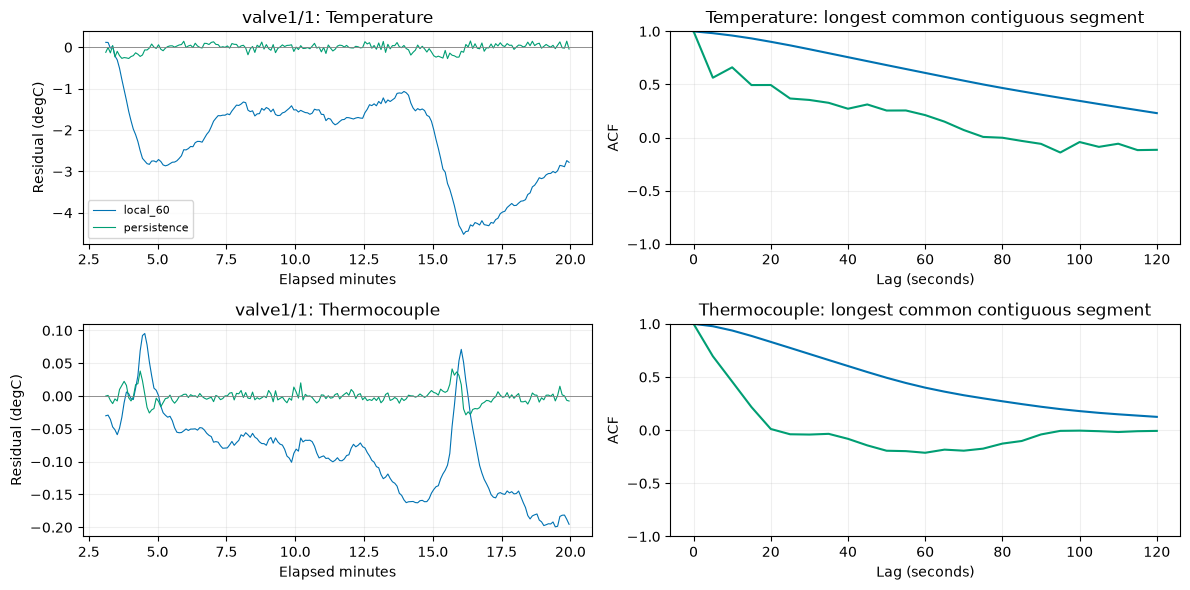

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
recording_id = settings["example_recording"]
for row, name in enumerate(thermal):
    models = thermal_predictions[recording_id, name]
    start = recordings[recording_id].timestamp.min()
    later = aggregates[recording_id].index-step >= start+pd.Timedelta(seconds=180)
    common = later & models["local_60"].residual.notna() & models["persistence"].residual.notna()
    for method in ["local_60", "persistence"]:
        residual = models[method].residual.where(common)
        axes[row, 0].plot((residual.index-start).total_seconds()/60, residual, label=method,
                          color=COLORS[method], linewidth=.8)
        curve, _ = segment_acf(residual, frequency, 24)
        axes[row, 1].plot(curve.lag_steps*step.total_seconds(), curve.acf, label=method, color=COLORS[method])
    axes[row, 0].set(title=f"{recording_id}: {name}", xlabel="Elapsed minutes", ylabel="Residual (degC)")
    axes[row, 1].set(title=f"{name}: longest common contiguous segment", xlabel="Lag (seconds)", ylabel="ACF", ylim=(-1,1))
    axes[row, 0].axhline(0, color="grey", linewidth=.6)
axes[0, 0].legend(fontsize=8)
finish_figure(fig, "thermal-residuals")

**Observed:** persistence has smaller MAE for both temperature signals in **all 25 available local-60 comparisons**. Typical paired reductions are **0.868°C** for motor temperature and **0.067°C** for fluid temperature. These refer to five-second averages, not individual sensor readings.

Residuals also become less strongly related to their immediate past. The median lag-five-second ACF falls from **0.966 to 0.179** for motor temperature and from **0.972 to 0.264** for fluid temperature. Some recordings still have substantial dependence; these are not automatically independent errors.

**Read the figure as two different descriptions of change.** The blue fixed residual can remain several degrees below zero: temperature is below its initial reference. The green persistence residual can stay near zero: temperature changes little from one window to the next. Both can be true while temperature has shifted considerably from its starting level.

Retain both views for Notebook 03. A good short-term prediction can follow a change we may want to detect. The four-method table excludes overlapping `other/5`; the local-60/persistence comparison includes it. An unavailable residual means no supported assessment, not a correct prediction.

## 6. Are levels changing, and is current repeating over time?

A **trend** is a changing level. **Autocorrelation (ACF)** describes how values relate to earlier values. **Periodicity** means a pattern repeats at a reasonably consistent interval. A slowly decaying ACF alone does not establish repetition.

Notebook 01 found that temperature's dependence on recent readings remains strong after removing a straight-line trend. Here, inspect changes in reference levels and residual spread, and examine possible repetition in `Current`.

For the current plots, compare the original series with a version after subtracting a straight line calculated within the viewed segment. This is a diagnostic made afterward, not a step used to calculate historical predictions. Each ACF uses one uninterrupted segment; separate files are never joined. Development portions end before the first annotation only for this diagnostic, not to choose calibration windows.

The table reports a positive local ACF peak between 20 and 120 seconds, where the segment is long enough. This is a candidate repeat interval to investigate, not an automatically selected seasonal model. Daily or weekly patterns cannot be established from these short, separate recordings.

In [23]:
periodic_rows, periodic_curves = [], {}
for recording_id in [normal_id, *development_ids]:
    means = aggregates[recording_id]
    valid = means.Current.where(continuity[recording_id].Current)
    if recording_id == normal_id:
        boundaries = [normal_start+span*i/3 for i in range(4)]
        portions = [(f"normal third {i+1}", boundaries[i], boundaries[i+1]) for i in range(3)]
    else:
        labels = annotations[recording_id].set_index("timestamp")
        first_mark = labels.index[labels.anomaly.eq(1) | labels.changepoint.eq(1)].min()
        portions = [(recording_id, recordings[recording_id].timestamp.min(), first_mark)]
    for portion, start, end in portions:
        selected = valid.loc[(valid.index-step >= start) & (valid.index <= end)]
        for detrended in [False, True]:
            curve, info = segment_acf(selected, frequency, 24, remove_linear_trend=detrended)
            periodic_curves[portion, detrended] = curve
            peaks = curve.loc[curve.acf.gt(curve.acf.shift()) & curve.acf.gt(curve.acf.shift(-1))
                              & curve.lag_steps.ge(4) & curve.acf.gt(0)]
            peak = peaks.loc[peaks.acf.idxmax()] if len(peaks) else None
            lag = peak.lag_steps*step.total_seconds() if peak is not None else np.nan
            periodic_rows.append({"portion": portion, "detrended": detrended, **info,
                                  "candidate_lag_s": lag, "peak_acf": peak.acf if peak is not None else np.nan,
                                  "segment_spans_candidate_cycles": (info["samples"]-1)*5/lag if lag > 0 else np.nan})

**Reading the repetition table:** `samples` counts five-second observations in the selected uninterrupted segment. `candidate_lag_s` is a possible repeat interval suggested by an ACF peak; `peak_acf` gives its strength. `segment_spans_candidate_cycles` is segment duration divided by that interval, not a count of verified repeated cycles. `NaN` means no candidate was reported under this diagnostic. The plots compare original and straight-line-adjusted ACF, without treating their peaks as established seasonal periods.

In [24]:
periodicity = pd.DataFrame(periodic_rows)
periodicity.to_csv(OUT / "current_periodicity.csv", index=False)
display(periodicity.loc[periodicity.detrended, ["portion", "samples", "candidate_lag_s", "peak_acf",
                                              "segment_spans_candidate_cycles"]].round(3))

,portion,samples,candidate_lag_s,peak_acf,segment_spans_candidate_cycles
1,normal third 1,426,40.0,0.099,53.125
3,normal third 2,663,40.0,0.095,82.750
5,normal third 3,663,45.0,0.098,73.556
7,other/1,115,55.0,0.435,10.364
9,other/10,118,45.0,0.183,13.000
11,other/11,118,100.0,0.187,5.850
13,other/13,68,45.0,0.129,7.444
15,other/14,118,95.0,0.185,6.158
17,other/2,20,NaN,NaN,NaN
19,other/3,118,55.0,0.128,10.636


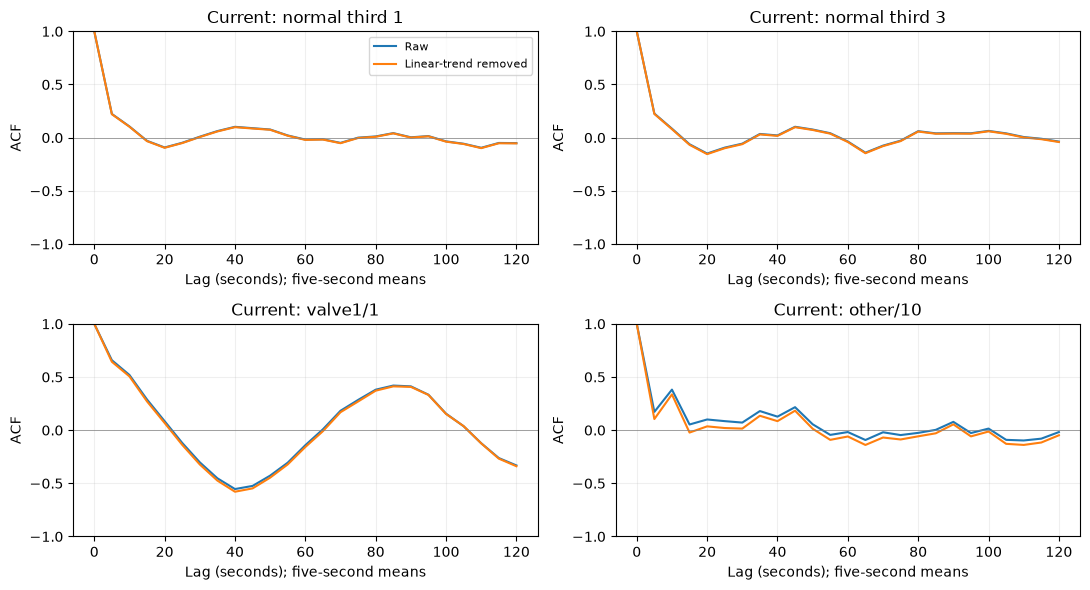

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, portion in zip(axes.flat, ["normal third 1", "normal third 3", "valve1/1", "other/10"]):
    for detrended in [False, True]:
        curve = periodic_curves[portion, detrended]
        ax.plot(curve.lag_steps*5, curve.acf, label="Linear-trend removed" if detrended else "Raw")
    ax.set(title=f"Current: {portion}", xlabel="Lag (seconds); five-second means", ylabel="ACF", ylim=(-1,1))
    ax.axhline(0, color="grey", linewidth=.5)
axes[0, 0].legend(fontsize=8)
finish_figure(fig, "current-periodicity")

**Does the departure change as a recording continues?** Divide the post-calibration portion of each recording into three equal elapsed-time blocks. Calculate the local-60 residual median and IQR in each block, then take medians across recordings. A more negative `median_residual` means readings sit further below their initial reference. A changing `residual_iqr` means their spread changes. These blocks are not aligned to intervention times.

In [26]:
# Equal elapsed thirds AFTER calibration: centre and spread of fixed residuals.
block_rows = []
for recording_id in development_ids:
    data = recordings[recording_id].set_index("timestamp")
    begin = data.index.min()+pd.Timedelta(seconds=180)
    end = data.index.max()+pd.Timedelta(settings["nominal_interval"])
    for name in measurements:
        for block in range(3):
            left, right = begin+(end-begin)*block/3, begin+(end-begin)*(block+1)/3
            residual = native_predictions[recording_id, name]["local_60"].residual
            values = residual.loc[(residual.index >= left) & (residual.index < right)].dropna()
            block_rows.append({"recording_id": recording_id, "measurement": name, "block": block+1,
                               "observations": len(values), "median_residual": values.median(),
                               "residual_iqr": values.quantile(.75)-values.quantile(.25)})
residual_blocks = pd.DataFrame(block_rows)
residual_blocks.to_csv(OUT / "fixed_residual_blocks.csv", index=False)
display(residual_blocks.groupby(["measurement", "block"])[["median_residual", "residual_iqr"]].median().round(5))
print("These blocks can contain interventions: changing spread is not automatically ordinary variance adaptation.")

median_residual  residual_iqr
measurement         block                               
Accelerometer1RMS   1              0.00001       0.00069
                    2              0.00009       0.00063
                    3              0.00020       0.00061
Accelerometer2RMS   1              0.00027       0.00181
                    2              0.00056       0.00184
                    3              0.00019       0.00156
Current             1             -0.04051       0.48029
                    2             -0.03746       0.47852
                    3             -0.03642       0.47117
Pressure            1              0.00000       0.32793
                    2              0.00000       0.32793
                    3              0.00000       0.32793
Temperature         1             -0.01190       0.48800
                    2             -0.53435       0.48203
                    3             -0.79605       0.49247
Thermocouple        1             -0.02275       0.02590
                    2             -0.03430       0.02620
                    3             -0.05540       0.02420
Voltage             1             -0.05200      11.82625
                    2             -0.18250      12.18975
                    3             -0.04300      12.60250
Volume Flow RateRMS 1              0.00000       0.67675
                    2             -1.00000       1.02010
                    3              0.00000       1.02010

These blocks can contain interventions: changing spread is not automatically ordinary variance adaptation.


**Observed:** current shows short repetition in the valve experiments. Candidate intervals cluster around **80–95 seconds**, with ACF peaks about **0.37–0.67** after removing a straight-line trend. The normal file has weaker peaks near **40–45 seconds**, around **0.10**. Other experiments give more varied intervals.

**Why no seasonal model here?** A 60-second calibration contains less than one typical valve cycle; 180 seconds contains only about two. The longer diagnostic portions reveal a possible pattern using observations beyond those cutoffs. They cannot supply a period for a reference claimed to use only the first 60 or 180 seconds. The separate normal file also does not establish a matching valve-cycle reference.

A future experiment with an explicitly longer fitting period could calculate a repeating reference and check it on later, unused data. We have not established daily or weekly seasonality, but we also have not concluded that SKAB lacks all repetition.

The residual-block table shows changing levels and spreads. Its intervals can include interventions, so automatically adjusting the reference to follow those changes could hide behaviour we want to investigate.

## 7. Does sensor 1 help explain sensor 2's vibration reading?

The target in this experiment is **Accelerometer2RMS**. Compare two descriptions of the same sensor-2 reading:

| Method | Comparison value for sensor 2 |
|---|---|
| Local median | Sensor 2's median during calibration. |
| `conditional_line` | A value calculated from sensor 1's reading **at the same time**, using a straight-line relationship calculated during calibration. |

The line has an intercept and a slope: `expected sensor 2 = intercept + slope × sensor 1`. Here, fitting means calculating those two coefficients, rather than a median.

First inspect whether calibration contains enough paired readings, whether sensor 1 varies, and whether the association remains similar across calibration halves and later pre-marked readings. Labels describe that later diagnostic portion; they are not prediction inputs.

The two preselected examples, `valve1/1` and `other/10`, showed consistently positive local association, so we examine a line in those cases only. Calculate it separately using 60 and 180 seconds, then compare with the matching sensor-2 median after 180 seconds. This is an exploratory check, not an automatic model-selection procedure for all recordings.

Because it needs sensor 1's current reading, the line describes a simultaneous relationship rather than a future forecast. Both vibration levels could change together while maintaining that relationship; individual-sensor residuals remain necessary.

**Reading the relationship audit:** `pairs` counts simultaneous calibration readings; `predictor_distinct` and `predictor_sd` describe variation in sensor 1. `rho` is Spearman correlation: positive means the readings tend to rise together, negative means they tend to move oppositely, and near zero means weak monotonic association. Compare the calibration halves and later pre-marked portion for consistency. `supported` checks coverage only; it does not approve the line as a model. Zero `later_pairs` means there are no later observations in that diagnostic portion, so its correlation is unavailable.

In [27]:
x_name, y_name = "Accelerometer1RMS", "Accelerometer2RMS"
relationship_rows = []
for recording_id in development_ids:
    data = recordings[recording_id].set_index("timestamp")
    start = data.index.min()
    later = data.loc[(data.index >= start+pd.Timedelta(seconds=180)) & phases[recording_id].eq("before_first_mark")]
    for seconds in options["calibration_seconds"]:
        end = start+pd.Timedelta(seconds=seconds)
        calibration_data = data.loc[data.index < end, [x_name, y_name]]
        half = start+pd.Timedelta(seconds=seconds/2)
        first, second = calibration_data.loc[calibration_data.index < half], calibration_data.loc[calibration_data.index >= half]
        relationship_rows.append({"recording_id": recording_id, "seconds": seconds,
            "supported": bool(calibrations[recording_id, seconds].loc[[x_name,y_name], "supported"].all()),
            "pairs": len(calibration_data.dropna()), "predictor_distinct": calibration_data[x_name].nunique(),
            "predictor_sd": calibration_data[x_name].std(),
            "calibration_rho": calibration_data[x_name].corr(calibration_data[y_name], method="spearman"),
            "first_half_rho": first[x_name].corr(first[y_name], method="spearman"),
            "second_half_rho": second[x_name].corr(second[y_name], method="spearman"),
            "later_pairs": len(later), "later_premark_rho": later[x_name].corr(later[y_name], method="spearman")})
relationship = pd.DataFrame(relationship_rows)
relationship.to_csv(OUT / "vibration_relationship_support.csv", index=False)
display(relationship.loc[relationship.seconds.eq(180)].round(4))

,recording_id,seconds,supported,pairs,predictor_distinct,predictor_sd,calibration_rho,first_half_rho,second_half_rho,later_pairs,later_premark_rho
1,other/1,180,True,172,171,0.0006,-0.7159,-0.7440,-0.7139,385,-0.6264
3,other/10,180,True,171,169,0.0025,0.5060,0.4496,0.5686,399,0.5305
5,other/11,180,True,172,171,0.0045,0.7130,0.7464,0.7250,398,0.7344
7,other/13,180,False,119,119,0.0040,0.6463,0.5621,0.7057,376,0.7062
9,other/14,180,True,172,171,0.0024,0.7252,0.7372,0.7301,399,0.7089
11,other/2,180,False,104,103,0.0006,-0.7411,-0.7693,-0.7132,0,NaN
13,other/3,180,True,171,171,0.0006,-0.5105,-0.5036,-0.5280,397,-0.5029
15,other/5,180,True,171,170,0.0024,0.4227,0.3555,0.3530,401,0.1385
17,other/6,180,True,172,170,0.0017,0.2478,0.2145,0.2624,401,0.2813
19,other/7,180,True,172,168,0.0025,0.6889,0.7277,0.6835,400,0.6808


In [28]:
pair_rows, pair_fit_rows, pair_residual_rows = [], [], []
for recording_id in options["examples"][:2]:
    data = recordings[recording_id].set_index("timestamp")
    start = data.index.min()
    for seconds in options["calibration_seconds"]:
        end = start+pd.Timedelta(seconds=seconds)
        assert calibrations[recording_id, seconds].loc[[x_name,y_name], "supported"].all()
        calibration_data = data.loc[data.index < end]
        fitted = fit_pair_reference(calibration_data[x_name], calibration_data[y_name])
        pair_fit_rows.append(dict(recording_id=recording_id, seconds=seconds, **fitted.to_dict()))
        later = data.loc[data.index >= start+pd.Timedelta(seconds=180)]
        expected = fitted.intercept+fitted.slope*later[x_name]
        prediction = pd.DataFrame({"expected": expected, "lower": np.nan, "upper": np.nan,
                                   "residual": later[y_name]-expected})
        extrapolated = ~later[x_name].between(fitted.predictor_min, fitted.predictor_max)
        fixed = native_predictions[recording_id, y_name][f"local_{seconds}"].reindex(later.index)
        for phase in ["all", *phases[recording_id].unique()]:
            selected = np.ones(len(later), dtype=bool) if phase == "all" else phases[recording_id].reindex(later.index).eq(phase)
            result = compare_predictions(later.loc[selected, y_name],
                {"local_median": fixed.loc[selected], "conditional_line": prediction.loc[selected]})
            pair_rows.append(result.assign(recording_id=recording_id, seconds=seconds, phase=phase,
                                           extrapolated_fraction=extrapolated.loc[selected].mean()))
        pair_residual_rows.append(prediction.assign(recording_id=recording_id, seconds=seconds,
            actual=later[y_name], predictor=later[x_name], extrapolated=extrapolated,
            phase=phases[recording_id].reindex(later.index)).reset_index())

**Compare both estimates against the same sensor-2 readings.** `local_median` uses its calibration median; `conditional_line` uses sensor 1's current value and the calibration line. `all` includes all later readings after 180 seconds; `before_first_mark` is the smaller pre-marked subset. `extrapolated_fraction` is the fraction of later sensor-1 readings outside its calibration minimum/maximum. It is repeated on both method rows to describe the shared evaluation population.

In the following scatterplots, orange points are 180-second calibration pairs, blue points are later pre-marked pairs, and the black line is the calculated relationship within its fitting range.

In [29]:
pair_results = pd.concat(pair_rows, ignore_index=True)
pair_results.to_csv(OUT / "vibration_comparisons.csv", index=False)
pd.DataFrame(pair_fit_rows).to_csv(OUT / "vibration_fits.csv", index=False)
pd.concat(pair_residual_rows, ignore_index=True).to_csv(OUT / "vibration_residuals.csv.gz", index=False)
display(pair_results.loc[pair_results.phase.isin(["all", "before_first_mark"]),
    ["recording_id", "seconds", "phase", "method", "common", "mae", "bias", "extrapolated_fraction"]].round(5))

,recording_id,seconds,phase,method,common,mae,bias,extrapolated_fraction
0,valve1/1,60,all,local_median,974,0.00089,0.00069,0.09240
1,valve1/1,60,all,conditional_line,974,0.00073,0.00052,0.09240
2,valve1/1,60,before_first_mark,local_median,401,0.00069,0.00044,0.05486
3,valve1/1,60,before_first_mark,conditional_line,401,0.00056,0.00033,0.05486
10,valve1/1,180,all,local_median,974,0.00077,0.00037,0.02259
11,valve1/1,180,all,conditional_line,974,0.00067,0.00035,0.02259
12,valve1/1,180,before_first_mark,local_median,401,0.00061,0.00012,0.01496
13,valve1/1,180,before_first_mark,conditional_line,401,0.00052,0.00017,0.01496
20,other/10,60,all,local_median,1156,0.00434,0.00283,0.45934
21,other/10,60,all,conditional_line,1156,0.00513,0.00379,0.45934


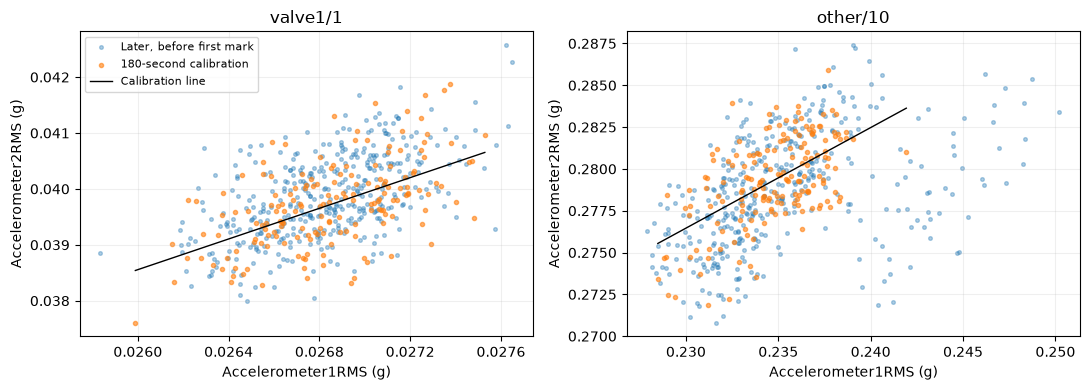

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, recording_id in zip(axes, options["examples"][:2]):
    data = recordings[recording_id].set_index("timestamp")
    start = data.index.min()
    cal = data.loc[data.index < start+pd.Timedelta(seconds=180)]
    later = data.loc[(data.index >= start+pd.Timedelta(seconds=180)) & phases[recording_id].eq("before_first_mark")]
    ax.scatter(later[x_name], later[y_name], s=7, alpha=.35, label="Later, before first mark")
    ax.scatter(cal[x_name], cal[y_name], s=9, alpha=.6, label="180-second calibration")
    fit = fit_pair_reference(cal[x_name], cal[y_name])
    grid = np.array([fit.predictor_min, fit.predictor_max])
    ax.plot(grid, fit.intercept+fit.slope*grid, color="black", linewidth=1, label="Calibration line")
    ax.set(title=recording_id, xlabel=f"{x_name} (g)", ylabel=f"{y_name} (g)")
    ax.xaxis.set_major_locator(MaxNLocator(5))
axes[0].legend(fontsize=8)
finish_figure(fig, "vibration-relationship")

**Observed:** the two vibration channels do not have one consistent relationship across recordings. Calibration associations can be positive, negative or weak, and some change between portions. Adequate coverage and varying readings alone do not establish a useful line.

In both selected examples, the line has smaller MAE on later pre-marked observations under both fitting durations. With 180 seconds, `valve1/1` changes from approximately **0.00061 to 0.00052 g**; `other/10` changes from **0.00279 to 0.00258 g**.

Across the full later interval, however, the line has larger error in `other/10`. About **34%** of its predictor readings lie outside the range seen during 180-second calibration; with 60 seconds, this reaches 46%.

These findings support retaining a limited relationship experiment, not declaring a universal model. A larger residual after an intervention might be useful for detection, while a smaller one might follow a shared change. Prediction error alone does not settle that question. We neither invent an uncertainty range for the line nor clip readings outside its fitting range.

## 8. What goes to Notebook 03?

We now have several explicit ways to describe departures. Local medians reduce differences in starting levels; temperature also benefits from a recent-history comparison. Pressure needs care with repeated values, and current's possible cycles need more fitting time before a repeating reference can be justified.

The next table recommends a representation for each signal. Its numerical columns describe **local-60 on the same readings as local-180 across 24 supported recordings**. These include `other/5`, so they can differ from the earlier 23-recording external-reference comparison. They are reference-quality results, not detection scores.

Saved residual tables include these fields:

| Field | Meaning for the next notebook |
|---|---|
| `actual`, `expected`, `residual` | Observation, method's comparison value, and their signed difference. |
| `lower`, `upper` | Empirical limits where calculated; not alert thresholds or safety limits. |
| `timestamp` | Original sample time, or the end/availability time of a five-second target. |
| `window_start`, `issued_at` | For thermal outputs, the target's start and when its prediction was issued. |
| `eligible` | Whether the prediction and observation can be scored. An earlier forecast can exist even when later data problems make this false. |
| `transfer_eligible` | Whether the recording passes the shared-row check for external comparison. This does not make experiments from one testbed statistically independent. |
| `NaN` | An unavailable value, not zero departure or proof of normal behaviour. |

Calibration tables record the fitting periods and support. Annotations are attached afterward for interpretation; they do not determine the references. The final message records where fitted values, comparisons, residuals and source/version information were saved.

**Notebook 03's task:** decide which departures are large or persistent enough to report, then evaluate those decisions. Keep the 60- and 180-second results visible until an operational calibration policy is agreed; failed calibration must not silently become a different method.

Limits remain: one testbed, short experiments, related observations, incomplete operating context, unknown timezone and no guarantee of healthy initial calibration. An empirical range describes recorded fitting values. A small prediction error can mean that a method follows a developing change rather than reveals it.

In [31]:
recommendations = pd.DataFrame([
    ["Accelerometer1RMS", "Local fixed centre/range; retain external reference for transfer audit", "Changing level/spread; paired relation only exploratory"],
    ["Accelerometer2RMS", "Local fixed centre/range; conditional residual only as complementary evidence", "Local relationships vary; shared change can escape the pair residual"],
    ["Current", "Local fixed centre/range", "Short-cycle evidence reviewed below; no universal seasonal model"],
    ["Pressure", "Empirical levels and fixed residual in bar", "Ties/zero MAD; do not standardise with an arbitrary epsilon"],
    ["Temperature", "Local fixed residual plus five-second persistence residual", "Recent history can hide a sustained level departure"],
    ["Thermocouple", "Local fixed residual plus five-second persistence residual", "Different thermal location; no imposed motor/fluid relationship"],
    ["Voltage", "Local fixed centre/range and blockwise spread", "No temporal model justified merely for consistency with other sensors"],
    ["Volume Flow RateRMS", "Local fixed centre/range, recorded-level frequencies", "External level mismatch; tied readings and zero MAD"],
], columns=["measurement", "carry_forward", "limitation"])
# Join actual per-recording evidence, rather than inferring findings from names.
evidence = local_results.loc[local_results.method.eq("local_60")].groupby("measurement").agg(
    compared_recordings=("mae", "count"), median_paired_mae=("mae", "median"),
    median_range_coverage=("range_coverage", "median"))
recommendations = recommendations.join(evidence, on="measurement")
recommendations.insert(1, "unit", recommendations.measurement.map(lambda name: METRICS[name].unit))
display(recommendations.round(5))
recommendations.to_csv(OUT / "handover.csv", index=False)

,measurement,unit,carry_forward,limitation,compared_recordings,median_paired_mae,median_range_coverage
0,Accelerometer1RMS,g,Local fixed centre/range; retain external refe...,Changing level/spread; paired relation only ex...,24,0.00040,0.74695
1,Accelerometer2RMS,g,Local fixed centre/range; conditional residual...,Local relationships vary; shared change can es...,24,0.00116,0.75242
2,Current,A,Local fixed centre/range,Short-cycle evidence reviewed below; no univer...,24,0.25892,0.86177
3,Pressure,bar,Empirical levels and fixed residual in bar,Ties/zero MAD; do not standardise with an arbi...,24,0.16641,0.94438
4,Temperature,degC,Local fixed residual plus five-second persiste...,Recent history can hide a sustained level depa...,24,0.84747,0.12005
5,Thermocouple,degC,Local fixed residual plus five-second persiste...,Different thermal location; no imposed motor/f...,24,0.07015,0.10182
6,Voltage,V,Local fixed centre/range and blockwise spread,No temporal model justified merely for consist...,24,8.21481,0.85282
7,Volume Flow RateRMS,L/min,"Local fixed centre/range, recorded-level frequ...",External level mismatch; tied readings and zer...,24,0.88317,0.59632


In [32]:
versions = {package: importlib.metadata.version(package) for package in ["numpy", "pandas", "matplotlib", "statsmodels", "nbclient"]}
run_manifest = {"source_commit": settings["source_commit"], "opened_files": [r for r in settings["files"] if r["partition"] != "reserved_test"],
                "reserved_ids_not_opened": sorted(reserved), "external_transfer_excluded": sorted(overlap_ids), "settings": options,
                "gap_threshold": settings["gap_threshold"], "nominal_interval": settings["nominal_interval"],
                "python": platform.python_version(), "packages": versions,
                "interpretation": "Development reference assessment; no detection rules or final-test evaluation"}
(OUT / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2)+"\n")
print("Saved fitted references, per-recording comparisons, residuals and provenance to", OUT.relative_to(ROOT))

Saved fitted references, per-recording comparisons, residuals and provenance to outputs/skab_baselines


## Methodological sources

- [Pinned SKAB documentation](https://github.com/waico/SKAB/blob/b2c0d46c2971dcbfe71e26087b6d231998bb91c2/README.md): source definitions and experimental scope. Our split, calibration durations and support rule are project choices, not official SKAB requirements.
- Hyndman & Athanasopoulos, [Forecasting: Principles and Practice — toolbox](https://otexts.com/fpp3/toolbox.html): simple persistence benchmarks, chronological evaluation and residual diagnostics (established statistical textbook).
- [Time-series graphics](https://otexts.com/fpp3/graphics.html): distinguish trend, autocorrelation and seasonal repetition. Descriptive patterns are hypotheses, not proof of a stable process.
- [statsmodels ACF](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.stattools.acf.html): implementation documentation. We use finite contiguous segments and omit IID significance bands.

These sources justify methods, not the numerical findings: the tables and figures above are produced from the pinned source files.